# Pace : Plan Stage

# Olist Discovery

answering the Discovery Mission questions:
1. What is happening in the business?
2. Where are the frictions or challenges?
3. What patterns or trends deserve attention?
4. What would management need to understand?
5. What evidence supports the conclusions?


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

# convert date columns
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## 1. What is happening in the business?

In [2]:
print(orders['order_status'].value_counts())


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


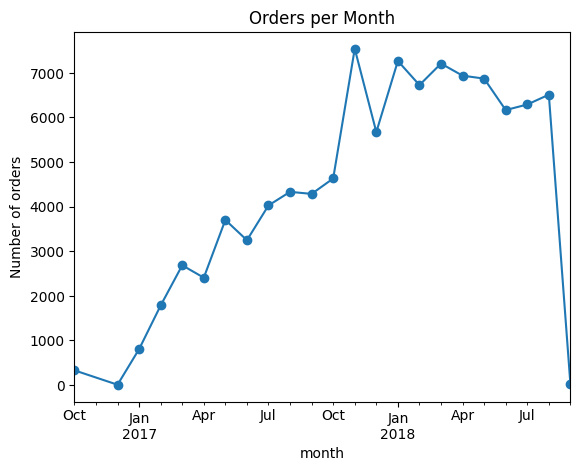

In [3]:
orders['month'] = orders['order_purchase_timestamp'].dt.to_period('M')
orders_per_month = orders['month'].value_counts().sort_index()
orders_per_month = orders_per_month.iloc[1:-1]  # drop first/last partial months

orders_per_month.plot(kind='line', marker='o', title='Orders per Month')
plt.ylabel('Number of orders')
plt.show()


In [4]:
revenue = items['price'].sum()
freight = items['freight_value'].sum()
avg_order_value = items.groupby('order_id')['price'].sum().mean()

print('Total revenue: R$', round(revenue, 2))
print('Total freight: R$', round(freight, 2))
print('Average order value: R$', round(avg_order_value, 2))


Total revenue: R$ 13591643.7
Total freight: R$ 2251909.54
Average order value: R$ 137.75


## 2. Where are the frictions or challenges?

In [5]:
delivered = orders[orders['order_status'] == 'delivered'].copy()
delivered['delivery_days'] = (delivered['order_delivered_customer_date'] - delivered['order_purchase_timestamp']).dt.days
delivered['late'] = delivered['order_delivered_customer_date'] > delivered['order_estimated_delivery_date']

print('Average delivery time (days):', round(delivered['delivery_days'].mean(), 1))
print('Percent of orders delivered late:', round(delivered['late'].mean() * 100, 1), '%')


Average delivery time (days): 12.1
Percent of orders delivered late: 8.1 %


late
False    4.293737
True     2.566494
Name: review_score, dtype: float64


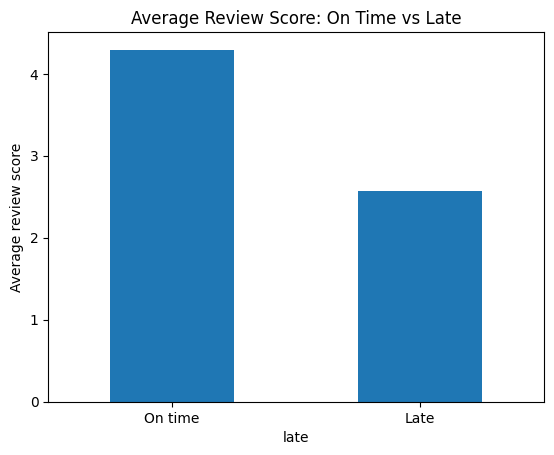

In [6]:
merged = delivered.merge(reviews[['order_id', 'review_score']], on='order_id')
avg_score_by_late = merged.groupby('late')['review_score'].mean()

print(avg_score_by_late)

avg_score_by_late.plot(kind='bar', title='Average Review Score: On Time vs Late')
plt.xticks([0, 1], ['On time', 'Late'], rotation=0)
plt.ylabel('Average review score')
plt.show()


In [7]:
# where are sellers vs customers located?
print('Top 5 seller states:')
print(sellers['seller_state'].value_counts(normalize=True).head(5) * 100)

print()
print('Top 5 customer states:')
print(customers['customer_state'].value_counts(normalize=True).head(5) * 100)


Top 5 seller states:
seller_state
SP    59.741519
PR    11.276252
MG     7.883683
SC     6.138934
RJ     5.525040
Name: proportion, dtype: float64

Top 5 customer states:
customer_state
SP    41.980672
RJ    12.924247
MG    11.700405
RS     5.496727
PR     5.073360
Name: proportion, dtype: float64


## 3. What patterns or trends deserve attention?

In [8]:
# how do customers pay?
print(payments['payment_type'].value_counts(normalize=True) * 100)

print()
print('Average installments on credit card:', round(payments[payments['payment_type']=='credit_card']['payment_installments'].mean(), 1))


payment_type
credit_card    73.922376
boleto         19.043952
voucher         5.558978
debit_card      1.471806
not_defined     0.002888
Name: proportion, dtype: float64

Average installments on credit card: 3.5


review_score
1    11.513344
2     3.175643
3     8.242965
4    19.291704
5    57.776344
Name: proportion, dtype: float64


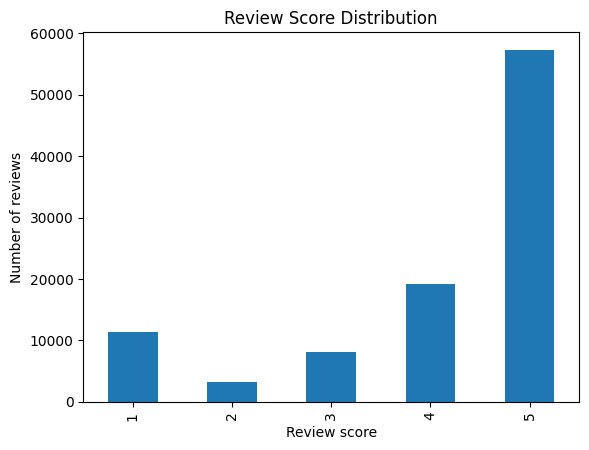

In [9]:
# distribution of review scores
print(reviews['review_score'].value_counts(normalize=True).sort_index() * 100)

reviews['review_score'].value_counts().sort_index().plot(kind='bar', title='Review Score Distribution')
plt.xlabel('Review score')
plt.ylabel('Number of reviews')
plt.show()


## 4. What would management need to understand?

- The business grew steadily over the two years in the data — order volume rose substantially, month over month.
- **Late deliveries hurt satisfaction a lot**: the average review score drops sharply when an order arrives late compared to on time.
- **Sellers are concentrated in São Paulo**, but customers are spread across the whole country — this geographic mismatch is likely a root cause of delivery delays for far-away states.
- Most customers pay by credit card and often split payments into several installments, showing price sensitivity.
- Review scores skew positive overall, but the negative reviews are concentrated around delivery problems.


## 5. Evidence supporting the conclusions

| Finding | Evidence |
|---|---|
| Business is growing | Monthly order count chart rises over the sample period |
| Late delivery hurts satisfaction | Average review score is clearly lower for late vs on-time orders |
| Seller/customer geography mismatch | Sellers concentrated in SP; customers spread nationally |
| Customers value flexible payment | ~74% pay by credit card, with several installments on average |
